# Assignment 3 – Digital options in the pricing library

| Task | Points |
| :- | :-: |
| a) `EuropeanDigitalContract`, `EuropeanDigitalAnalyticPricer` (fair value and greeks), pytest unit test for fair value | 12 |
| b) Figure: a digital call is the limit of bull call spreads | 8 |

The folder starts from the lecture's `solution` folder. Changes: `EuropeanDigitalContract` at the end of `contract.py`,
`EuropeanDigitalAnalyticPricer` at the end of `pricer.py`, new tests in `test_pricer.py`, and `conftest.py`, which puts the repository root on the path
so that `src.enums` is found when pytest runs from any folder:
```
pytest "homeworks/05923fb/Assignment 3"
```

## a) European digital option

Cash-or-nothing digital paying 1 unit of cash: call $\mathbb{1}\{S_T > K\}$, put $\mathbb{1}\{S_T < K\}$. Under Black–Scholes, with $\tau = T - t$:
$$ DC = e^{-r\tau} N(d_2), \qquad DP = e^{-r\tau} N(-d_2), \qquad DC + DP = e^{-r\tau}. $$

Greeks of the digital call ($\varphi$: standard normal density, $DF = e^{-r\tau}$, theta as $\partial V / \partial t$ like in `EuropeanAnalyticPricer`):

| $\Delta$ | $\Gamma$ | $\mathcal{V}$ | $\Theta$ | $\rho$ |
| :-: | :-: | :-: | :-: | :-: |
| $\dfrac{DF\,\varphi(d_2)}{S\sigma\sqrt{\tau}}$ | $-\dfrac{DF\,\varphi(d_2)\,d_1}{S^2\sigma^2\tau}$ | $-\dfrac{DF\,\varphi(d_2)\,d_1}{\sigma}$ | $r\,DF\,N(d_2) + DF\,\varphi(d_2)\left(\dfrac{d_1}{2\tau} - \dfrac{r}{\sigma\sqrt{\tau}}\right)$ | $-\tau\,DF\,N(d_2) + \dfrac{DF\,\varphi(d_2)\sqrt{\tau}}{\sigma}$ |

Put greeks from the parity: $\Delta, \Gamma, \mathcal{V}$ change sign, $\Theta_P = r\,DF - \Theta_C$, $\rho_P = -\tau\,DF - \rho_C$.

`EuropeanDigitalContract` derives from `Contract`, not from `EuropeanContract`: otherwise it would pass the type check of `EuropeanAnalyticPricer` and could be priced as a vanilla by mistake.

**Unit tests** (both stocks, $K/S_0 \in \{0.5, 0.9, 1, 1.1, 1.5\}$, $T \in \{0.25, 1, 2.5\}$):
* fair value: digital parity $DC + DP = DF$; short $= -$long; $DC = -\partial C / \partial K$ against a centered call spread priced with `EuropeanAnalyticPricer` (independent implementation, tolerance $10^{-9}$);
* greeks: all five against bump-and-revaluation finite differences, call and put, long and short (relative tolerance $10^{-4}$);
* contract: payoffs, rejected derivative type, each pricer rejects the other's contract.

In [1]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pricer import *

result = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', str(current)],
                        capture_output=True, text=True)
print(result.stdout.strip().splitlines()[-1])

QuantCourseBP a6915b9c65080f7003aa1e7b0fa8b8a349f17cf2*


274 passed in 2.35s


Example: at-the-money ($K = S_0$), one-year digitals.

In [2]:
params = Params()
rows = {}
for underlying in (Stock.BLUECHIP_BANK, Stock.TIPTOP_SOLUTIONS):
    model = MarketModel(underlying)
    for derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
        pricer = EuropeanDigitalAnalyticPricer(
            EuropeanDigitalContract(underlying, derivative_type, LongShort.LONG, model.spot, 1.0), model, params)
        rows[(underlying.value, derivative_type.value)] = {
            'fair value': pricer.calc_fair_value(), 'delta': pricer.calc_delta(), 'gamma': pricer.calc_gamma(),
            'vega': pricer.calc_vega(), 'theta': pricer.calc_theta(), 'rho': pricer.calc_rho()}
pd.DataFrame(rows).T

fair value     delta     gamma      vega     theta  \
BLUECHIP_BANK    CALL    0.453137  0.007638 -0.000050 -0.319892  0.033882   
                 PUT     0.498092 -0.007638  0.000050  0.319892  0.013679   
TIPTOP_SOLUTIONS CALL    0.474192  0.006688 -0.000037 -0.375036  0.024421   
                 PUT     0.477038 -0.006688  0.000037  0.375036  0.023140   

                            rho  
BLUECHIP_BANK    CALL  0.541140  
                 PUT  -1.492370  
TIPTOP_SOLUTIONS CALL  0.711693  
                 PUT  -1.662922

## b) Digital call as the limit of bull call spreads

A bull call spread (long call $K_1$, short call $K_2 > K_1$) pays a ramp from 0 to $h = K_2 - K_1$. Scaled by $1/h$, it is a ramp from 0 to 1,
which tends to the digital payoff $\mathbb{1}\{S_T > K\}$ as $h \to 0$:
$$ DC(K) = \lim_{h \to 0} \frac{C(K - h) - C(K)}{h} = -\frac{\partial C}{\partial K}. $$

* $(K_1, K_2) = (K - h, K)$: payoff $\ge$ digital payoff, so its price is an **upper bound** for every $h$;
* $(K_1, K_2) = (K, K + h)$: payoff $\le$ digital payoff, a **lower bound**.

The spreads are priced with two `EuropeanContract`s (long and short) and `EuropeanAnalyticPricer`, the digital with `EuropeanDigitalAnalyticPricer`.

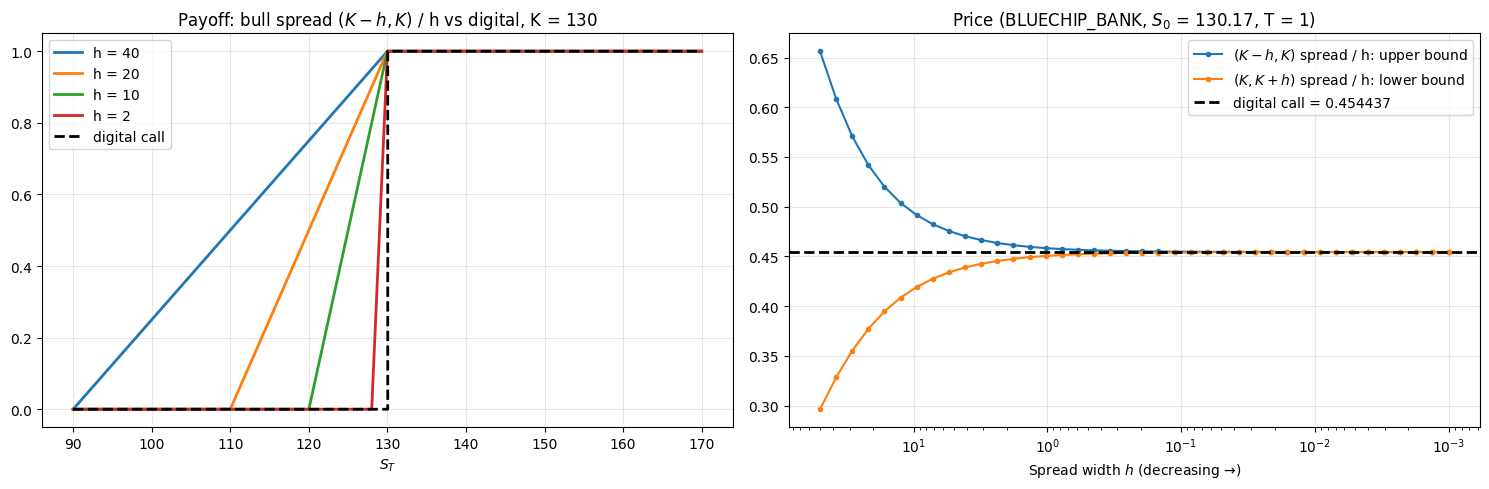

h = 0.001: upper - digital = 3.82e-06, digital - lower = 3.82e-06


In [3]:
def scaled_bull_spread_price(underlying: Stock, low_strike: float, high_strike: float, expiry: float) -> float:
    model = MarketModel(underlying)
    legs = [EuropeanContract(underlying, PutCallFwd.CALL, LongShort.LONG, low_strike, expiry),
            EuropeanContract(underlying, PutCallFwd.CALL, LongShort.SHORT, high_strike, expiry)]
    return sum(EuropeanAnalyticPricer(leg, model, params).calc_fair_value() for leg in legs) / (high_strike - low_strike)


underlying, strike, expiry = Stock.BLUECHIP_BANK, 130.0, 1.0
model = MarketModel(underlying)
digital = EuropeanDigitalAnalyticPricer(
    EuropeanDigitalContract(underlying, PutCallFwd.CALL, LongShort.LONG, strike, expiry), model, params).calc_fair_value()

widths = np.logspace(np.log10(50), -3, 40)
upper = [scaled_bull_spread_price(underlying, strike - h, strike, expiry) for h in widths]
lower = [scaled_bull_spread_price(underlying, strike, strike + h, expiry) for h in widths]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

s_T = np.linspace(strike - 40, strike + 40, 2001)
for h in (40, 20, 10, 2):
    axes[0].plot(s_T, (np.maximum(s_T - strike + h, 0) - np.maximum(s_T - strike, 0)) / h, linewidth=2, label=f'h = {h:g}')
axes[0].step(s_T, (s_T > strike).astype(float), where='post', color='black', linestyle='--', linewidth=2, label='digital call')
axes[0].set_title(f'Payoff: bull spread $(K - h, K)$ / h vs digital, K = {strike:g}')
axes[0].set_xlabel('$S_T$')

axes[1].plot(widths, upper, 'o-', markersize=3, label='$(K - h, K)$ spread / h: upper bound')
axes[1].plot(widths, lower, 'o-', markersize=3, label='$(K, K + h)$ spread / h: lower bound')
axes[1].axhline(digital, color='black', linestyle='--', linewidth=2, label=f'digital call = {digital:.6f}')
axes[1].set_xscale('log')
axes[1].invert_xaxis()
axes[1].set_title(f'Price ({underlying.value}, $S_0$ = {model.spot}, T = {expiry:g})')
axes[1].set_xlabel('Spread width $h$ (decreasing →)')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
print(f'h = {widths[-1]:g}: upper - digital = {upper[-1] - digital:.2e}, digital - lower = {digital - lower[-1]:.2e}')

**Conclusion.** As $h \to 0$ the scaled spread payoff tends to the digital step, and the spread prices from `EuropeanAnalyticPricer` squeeze the price of
`EuropeanDigitalAnalyticPricer` from above and below, with an error of order $h$ (about $4 \cdot 10^{-6}$ at $h = 0.001$).
This is the static replication of the digital, $DC = -\partial C / \partial K$, and the reason why digitals are risk-managed as tight call spreads in practice
(usually the conservative, upper one): the exact digital has unbounded delta at the strike close to expiry.